In [1]:
print("Credit Risk Analytics Project")
print("Mcom Fintech and Analytics")


Credit Risk Analytics Project
Mcom Fintech and Analytics


In [2]:
name="Credit Risk Analytics"
course="Mcom Fintech and Analytics"
print(name)
print(course)

Credit Risk Analytics
Mcom Fintech and Analytics


In [3]:
income=45000
loan_amount=300000
age=28
print("Income:",income)
print("Loan Amount:",loan_amount)
print("Age:",age)

Income: 45000
Loan Amount: 300000
Age: 28


In [4]:
loan_to_income=loan_amount/income
print("Loan to Monthly Income Ratio:",loan_to_income)

Loan to Monthly Income Ratio: 6.666666666666667


In [5]:
import pandas as pd
df= pd.read_csv("Loan_default.csv")
df.head()

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [6]:
df.shape

(255347, 18)

In [7]:
df.columns

Index(['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore',
       'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm',
       'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus',
       'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner',
       'Default'],
      dtype='str')

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  str    
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  str    
 11  EmploymentType  255347 non-null  str    
 12  MaritalStatus   255347 non-null  str    
 13  HasMortgage     255347 non-null  str    
 14  HasDependents   255347 non-null  str    
 15  LoanPurpose     255347 non-null  str    
 16  HasCoSigner     255347 non-null  str    
 17  Default         25534

In [9]:
df["Default"].value_counts()

Default
0    225694
1     29653
Name: count, dtype: int64

In [10]:
df["Default"].value_counts(normalize=True)*100

Default
0    88.387175
1    11.612825
Name: proportion, dtype: float64

In [11]:
df.groupby("Default")["Income"].mean()

Default
0    83899.165995
1    71844.722659
Name: Income, dtype: float64

In [12]:
df.groupby("Default")["LoanAmount"].mean()

Default
0    125353.656017
1    144515.311469
Name: LoanAmount, dtype: float64

In [13]:
df.groupby("Default")["DTIRatio"].mean()

Default
0    0.498602
1    0.512467
Name: DTIRatio, dtype: float64

In [14]:
df.groupby("Default")["CreditScore"].mean()

Default
0    576.232270
1    559.286143
Name: CreditScore, dtype: float64

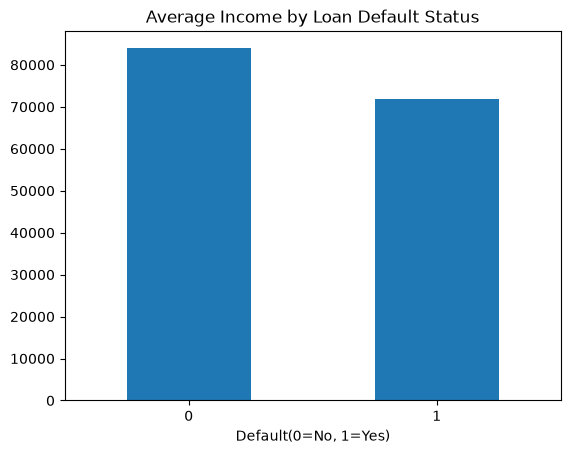

In [15]:
import matplotlib.pyplot as plt
income_by_default= df.groupby("Default")["Income"].mean()
income_by_default.plot(kind="bar")
plt.title("Average Income by Loan Default Status")
plt.xlabel("Default(0=No, 1=Yes)")
plt.xticks(rotation=0)
plt.show()

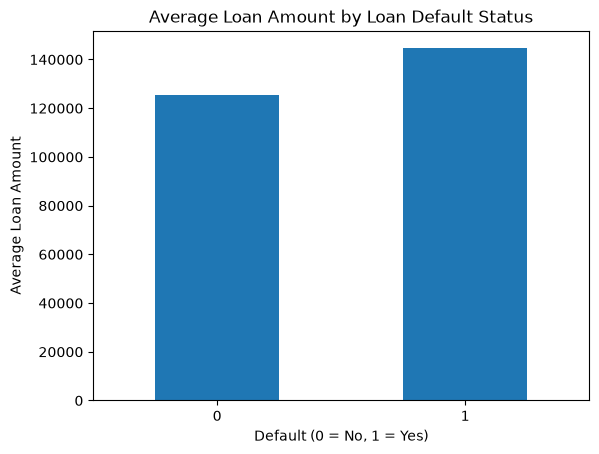

In [16]:
loan_by_default = df.groupby("Default")["LoanAmount"].mean()
loan_by_default.plot(kind="bar")
plt.title("Average Loan Amount by Loan Default Status")
plt.xlabel("Default (0 = No, 1 = Yes)")
plt.ylabel("Average Loan Amount")
plt.xticks(rotation=0)
plt.show()

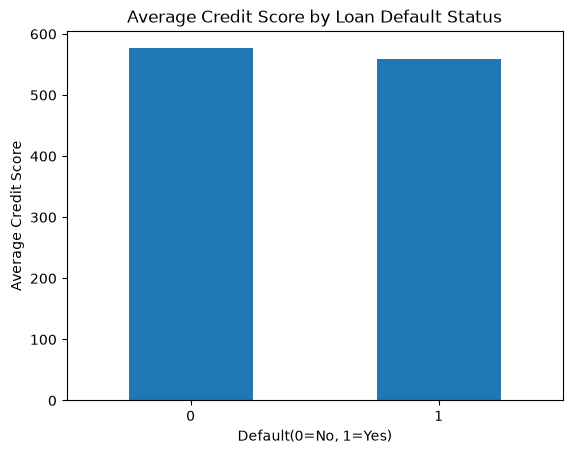

In [17]:
credit_by_default =df.groupby("Default")["CreditScore"].mean()
credit_by_default.plot(kind="bar")
plt.title("Average Credit Score by Loan Default Status")
plt.xlabel("Default(0=No, 1=Yes)")
plt.ylabel("Average Credit Score")
plt.xticks(rotation=0)
plt.show()



In [18]:
df.groupby("EmploymentType")["Default"].mean()*100

EmploymentType
Full-time         9.463366
Part-time        11.965213
Self-employed    11.462029
Unemployed       13.552895
Name: Default, dtype: float64

In [19]:
import sqlite3

In [20]:
conn=sqlite3.connect("credit_risk.db")

In [21]:
df.to_sql("loan_data",conn,if_exists="replace",index=False)

255347

In [22]:
pd.read_sql("SELECT *FROM loan_data LIMIT 5", conn)

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [23]:
query = """
SELECT AVG(Income)
FROM loan_data
WHERE [Default] =1;
"""
pd.read_sql(query,conn)

,AVG(Income)
0,71844.722659


In [24]:
query ="""
SELECT [Default],AVG(Income) AS Average_Income
FROM loan_data
GROUP BY [Default];
"""
pd.read_sql(query, conn)

,Default,Average_Income
0,0,83899.165995
1,1,71844.722659


In [25]:
query ="""
SELECT COUNT(*) AS Defaulted_Customers
FROM loan_data
WHERE [Default]= 1;
"""
pd.read_sql(query, conn)

,Defaulted_Customers
0,29653


In [26]:
query ="""
SELECT
    EmploymentType,
    COUNT(*) AS Total_Customers,
    SUM([Default]) AS Defaulted_Customers,
    AVG([Default])* 100 AS Default_Rate
FROM loan_data
GROUP BY EmploymentType
ORDER BY Default_Rate DESC;
"""
pd.read_sql(query, conn)

,EmploymentType,Total_Customers,Defaulted_Customers,Default_Rate
0,Unemployed,63824,8650,13.552895
1,Part-time,64161,7677,11.965213
2,Self-employed,63706,7302,11.462029
3,Full-time,63656,6024,9.463366


In [27]:
query ="""
SELECT 
    CASE
        WHEN CreditScore < 500 THEN 'Low Credit Score'
        WHEN CreditScore < 650 THEN 'Medium Credit Score'
        ELSE 'High Credit Score'
    END AS Credit_Risk_Category,
    COUNT(*) AS Total_Customers,
    SUM([Default]) AS Defaulted_Customers,
    AVG([Default]) * 100 AS Default_Rate
FROM loan_data
GROUP BY Credit_Risk_Category
ORDER BY Default_Rate DESC;
"""

pd.read_sql(query, conn)
    

,Credit_Risk_Category,Total_Customers,Defaulted_Customers,Default_Rate
0,Low Credit Score,93029,11883,12.773436
1,Medium Credit Score,69737,8101,11.616502
2,High Credit Score,92581,9669,10.443828


In [28]:
query = """
SELECT
    CASE
        WHEN LoanAmount < 100000 THEN 'Small Loan'
        WHEN LoanAmount < 200000 THEN 'Medium Loan'
        ELSE 'Large Loan'
    END AS Loan_Size_Category,
    COUNT(*) AS Total_Customers,
    SUM([Default]) AS Defaulted_Customers,
    AVG([Default]) * 100 AS Default_Rate
FROM loan_data
GROUP BY Loan_Size_Category
ORDER BY Default_Rate DESC;
"""

pd.read_sql(query, conn)

,Loan_Size_Category,Total_Customers,Defaulted_Customers,Default_Rate
0,Large Loan,52421,8275,15.785658
1,Medium Loan,103860,12675,12.203928
2,Small Loan,99066,8703,8.785052


In [29]:
query ="""
SELECT
    CASE
        WHEN DTIRatio < 0.4 THEN 'Low DTI'
        WHEN DTIRatio < 0.6 THEN 'Medium DTI'
        ELSE 'High DTI'
    END AS DTI_Category,
    COUNT(*) AS Total_Customers,
    SUM([Default]) AS Defaulted_Customers,
    AVG([Default])*100 AS Default_Rate
FROM loan_data
GROUP BY DTI_Category
ORDER BY Default_Rate DESC;
"""
pd.read_sql(query, conn)

,DTI_Category,Total_Customers,Defaulted_Customers,Default_Rate
0,High DTI,97536,11930,12.231381
1,Medium DTI,63722,7456,11.700825
2,Low DTI,94089,10267,10.912009


In [30]:
x = df.drop(columns=["LoanID","Default"])
y=df["Default"]
print("x shape:",x.shape)
print("y shape:",y.shape)

x shape: (255347, 16)
y shape: (255347,)


In [31]:
x.dtypes

Age                 int64
Income              int64
LoanAmount          int64
CreditScore         int64
MonthsEmployed      int64
NumCreditLines      int64
InterestRate      float64
LoanTerm            int64
DTIRatio          float64
Education             str
EmploymentType        str
MaritalStatus         str
HasMortgage           str
HasDependents         str
LoanPurpose           str
HasCoSigner           str
dtype: object

In [32]:
x_encoded = pd.get_dummies(x, drop_first=True)
print("Original columns:",x.shape[1])
print("Encoded columns:",x_encoded.shape[1])

Original columns: 16
Encoded columns: 24


In [33]:
x_encoded = pd.get_dummies(x, drop_first=True)

print(x_encoded.shape)

(255347, 24)


In [34]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x_encoded, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (204277, 24)
Testing data: (51070, 24)


In [35]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(x_train, y_train)

print("Model training completed!")

Model training completed!


D:\2nd sem\anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [36]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=2000)

model.fit(x_encoded, y)

print("Model training completed!")

Model training completed!


D:\2nd sem\anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [37]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler = StandardScaler()
train_data = scaler.fit_transform(x_train)
test_data = scaler.transform(x_test)

model = LogisticRegression(max_iter=1000)
model.fit(train_data, y_train)

print("Model training completed!")


Model training completed!


In [38]:
predictions = model.predict(test_data)

print(predictions[:10])

[0 0 0 0 0 0 0 0 0 0]


In [39]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, predictions)

print("Model Accuracy:", accuracy * 100, "%")


Model Accuracy: 88.5275112590562 %


In [40]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, predictions))

[[45009   130]
 [ 5729   202]]


In [41]:
from sklearn.metrics import recall_score

recall = recall_score(y_test, predictions)

print("Default Detection Rate:", recall * 100, "%")


Default Detection Rate: 3.405833754847412 %


In [42]:
model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)
model.fit(train_data, y_train)

predictions = model.predict(test_data)

print("Improved model training completed!")


Improved model training completed!


In [43]:
recall = recall_score(y_test, predictions)

print("New Default Detection Rate:", recall * 100, "%")

New Default Detection Rate: 69.93761591637161 %


In [44]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, predictions)
print("New Model Accuracy:", accuracy * 100, "%")

New Model Accuracy: 67.65028392402584 %


In [46]:
import pandas as pd
results = pd.DataFrame({
    "Model": ["Original Model", "Improved Model"],
    "Accuracy (%)": [88.53, 67.65],
    "Default Detection (%)": [3.41, 69.94]
})

results


,Model,Accuracy (%),Default Detection (%)
0,Original Model,88.53,3.41
1,Improved Model,67.65,69.94


In [47]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, predictions)
print(cm)


[[30401 14738]
 [ 1783  4148]]


In [48]:
from sklearn.metrics import precision_score
precision = precision_score(y_test, predictions)
print("Precision:", precision * 100, "%")


Precision: 21.963359101980302 %


In [49]:
from sklearn.metrics import f1_score
f1 = f1_score(y_test, predictions)
print("F1 Score:", f1)

F1 Score: 0.3342869806987146


In [50]:
performance = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Result (%)": [
        accuracy_score(y_test, predictions) * 100,
        precision_score(y_test, predictions) * 100,
        recall_score(y_test, predictions) * 100,
        f1_score(y_test, predictions) * 100
    ]
})
performance

,Metric,Result (%)
0,Accuracy,67.650284
1,Precision,21.963359
2,Recall,69.937616
3,F1 Score,33.428698


Project Summary
1. Project Overview

This project focuses on analysing loan customer data to identify patterns associated with loan defaults and develop a machine learning model to predict potential loan defaults. The objective is to understand customer credit risk, explore financial and demographic factors associated with default, and demonstrate how data analytics can support credit risk assessment and lending decisions.The project uses Python for data analysis and machine learning, SQL for querying customer and loan data. A Power BI dashboard will be developed to present key performance indicators and credit risk insights interactively.
Loan defaults can result in financial losses for banks and lending institutions. Analysing customer characteristics, loan amounts, credit scores, income, employment types, and debt-to-income ratios can help identify patterns associated with higher default rates.

2. Key Findings

The dataset contains 255,347 loan records, of which 29,653 are default cases. The overall default rate is approximately 11.61%.Average income was approximately 71,845 among defaulters and 83,899 among non-defaulters.Average loan amount was approximately 144,515 among defaulters and 125,354 among non-defaulters.Average credit score was approximately 559 among defaulters and 576 among non-defaulters.Unemployed customers had an observed default rate of approximately 13.55%, compared with 9.46% for full-time employees.Customers with large loans had an observed default rate of approximately 15.79%, compared with 8.79% for small loans.

3. Model Performance

A Logistic Regression model was developed to classify loan default outcomes. The dataset was divided into training and testing sets, categorical variables were encoded, and numerical features were standardised.The initial model achieved 88.53% accuracy but only 3.41% recall for the default class.
Model Evaluation Results-
The improved model achieved the following results on the test dataset:
Accuracy: 67.65% — The percentage of all predictions that were correct.
Precision: 21.96% — The percentage of customers predicted to default who actually defaulted.
Recall: 69.94% — The percentage of actual loan defaulters correctly identified by the model.
F1-score: 33.43% — A combined measure of precision and recall.
Interpretation-
Class balancing increased the model's recall from 3.41% to 69.94%, enabling it to identify a much larger proportion of actual loan defaulters. However, precision was 21.96%, indicating that many customers predicted to default did not actually default.
These results demonstrate the importance of evaluating classification models using multiple performance metrics rather than accuracy alone. Further model tuning and validation are required to improve precision while maintaining useful default detection. The model should be treated as a decision-support tool, not as the sole basis for lending decisions


4. Business Recommendations
Lending institutions should consider multiple factors, including income, credit score, existing debt obligations, loan amount, and repayment capacity, when assessing a customer's credit risk.
 The analysis identified higher observed default rates among unemployed customers and customers with larger loans. Lenders could monitor these segments more closely while assessing each applicant individually and avoiding decisions based solely on employment category or loan size.
 The improved Logistic Regression model achieved 69.94% recall but only 21.96% precision. This indicates that it identifies many actual defaulters but also incorrectly flags many non-defaulters. Model evaluation should therefore consider precision, recall, F1-score, and the confusion matrix in addition to accuracy.
 Further model tuning and testing should aim to improve precision while maintaining an acceptable level of default detection. The choice of decision threshold should reflect the relative costs of missed defaults and incorrectly flagged customers.
The model should be used as a decision-support tool rather than as the sole basis for approving or rejecting loans. Further validation, fairness assessment, and monitoring are necessary before practical deployment.

5. Model Performance

A Logistic Regression model was developed to classify loan default outcomes. The dataset was divided into training and testing sets, categorical variables were encoded, and numerical features were standardised.The initial model achieved 88.53% accuracy but only 3.41% recall for the default class.
Model Evaluation Results-
The improved model achieved the following results on the test dataset:
Accuracy: 67.65% — The percentage of all predictions that were correct.
Precision: 21.96% — The percentage of customers predicted to default who actually defaulted.
Recall: 69.94% — The percentage of actual loan defaulters correctly identified by the model.
F1-score: 33.43% — A combined measure of precision and recall.
Interpretation-
Class balancing increased the model's recall from 3.41% to 69.94%, enabling it to identify a much larger proportion of actual loan defaulters. However, precision was 21.96%, indicating that many customers predicted to default did not actually default.
These results demonstrate the importance of evaluating classification models using multiple performance metrics rather than accuracy alone. Further model tuning and validation are required to improve precision while maintaining useful default detection. The model should be treated as a decision-support tool, not as the sole basis for lending decisions

6. Conclusion

This project demonstrates the application of Python, SQL, exploratory data analysis, and machine learning to a credit risk analytics problem. It identifies patterns associated with loan defaults, compares the performance of two Logistic Regression models, and highlights the trade-off between identifying actual defaulters and flagging non-defaulters.The analysis provides a foundation for a credit risk reporting dashboard and demonstrates practical skills relevant to credit risk analysis.
